In [1]:
import numpy as np, pandas as pd, os, shutil, random, cv2
import matplotlib.pyplot as plt

DATASET_DIR = "/kaggle/input/datasets/sifatkhan69/bangladeshi-vehicle-license-plate/Bangladeshi_Vehicle_Image_with_visible_license_plate"
all_files = os.listdir(DATASET_DIR)
image_files = sorted([f for f in all_files if f.lower().endswith(('.jpg','.jpeg','.png'))])
label_files = sorted([f for f in all_files if f.endswith('.txt')])

img_stems = {os.path.splitext(f)[0] for f in image_files}
lbl_stems = {os.path.splitext(f)[0] for f in label_files}
matched_stems = img_stems & lbl_stems
stem_to_ext = {os.path.splitext(f)[0]: os.path.splitext(f)[1] for f in image_files}

work_dir = "/kaggle/working/dataset"
shutil.rmtree(work_dir, ignore_errors=True)
os.makedirs(f"{work_dir}/images", exist_ok=True)
os.makedirs(f"{work_dir}/labels", exist_ok=True)
for stem in matched_stems:
    ext = stem_to_ext[stem]
    shutil.copy(os.path.join(DATASET_DIR, stem+ext), f"{work_dir}/images/{stem}{ext}")
    shutil.copy(os.path.join(DATASET_DIR, stem+".txt"), f"{work_dir}/labels/{stem}.txt")

random.seed(42)
stems_list = list(matched_stems); random.shuffle(stems_list)
split_idx = int(0.8*len(stems_list))
train_stems, val_stems = stems_list[:split_idx], stems_list[split_idx:]
for split_name, stems in [("train",train_stems),("val",val_stems)]:
    os.makedirs(f"{work_dir}/{split_name}/images", exist_ok=True)
    os.makedirs(f"{work_dir}/{split_name}/labels", exist_ok=True)
    for stem in stems:
        ext = stem_to_ext[stem]
        shutil.copy(f"{work_dir}/images/{stem}{ext}", f"{work_dir}/{split_name}/images/{stem}{ext}")
        shutil.copy(f"{work_dir}/labels/{stem}.txt", f"{work_dir}/{split_name}/labels/{stem}.txt")

with open(f"{work_dir}/data.yaml","w") as f:
    f.write(f"train: {work_dir}/train/images\nval: {work_dir}/val/images\nnc: 1\nnames: ['license_plate']\n")

print("Train:", len(train_stems), "| Val:", len(val_stems))

Train: 1543 | Val: 386


In [2]:
!pip install -q ultralytics
from ultralytics import YOLO

model_base = YOLO('yolov8n.pt')
model_base.train(data=f'{work_dir}/data.yaml', epochs=50, imgsz=640, batch=16,
                  project='/kaggle/working/runs', name='baseline_clean')
model_base = YOLO('/kaggle/working/runs/baseline_clean/weights/best.pt')

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 42.1/42.1 kB 1.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 23.9 MB/s eta 0:00:00
Creating new Ultralytics Settings v0.0.6 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart/#ultralytics-settings.
Ultralytics 8.4.93 🚀 Python-3.12.13 torch-2.10.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/kaggle/working/dataset/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dis=6.0, distill_model=None, dnn=False, dropout=0.0

libpng warning: iCCP: profile 'ICC Profile': 0h: PCS illuminant is not D50


Plotting labels to /kaggle/working/runs/baseline_clean/labels.jpg... 
Image sizes 640 train, 640 val
Using 2 dataloader workers
Logging results to /kaggle/working/runs/baseline_clean
Starting training for 50 epochs...

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
       1/50      1.99G      1.456      2.525      1.392         39        640: 50% ━━━━━━────── 49/97 5.8it/s 11.7s<8.2s

libpng warning: iCCP: profile 'ICC Profile': 0h: PCS illuminant is not D50


       1/50      2.01G      1.438      2.015      1.347         13        640: 100% ━━━━━━━━━━━━ 97/97 4.2it/s 23.1s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 13/13 3.3it/s 4.0s
                   all        386        394      0.592      0.662      0.568      0.301


libpng warning: iCCP: profile 'ICC Profile': 0h: PCS illuminant is not D50


... (197 outputs left out)

libpng warning: iCCP: profile 'ICC Profile': 0h: PCS illuminant is not D50


                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 13/13 3.6it/s 3.6s


libpng warning: iCCP: profile 'ICC Profile': 0h: PCS illuminant is not D50


                   all        386        394      0.958      0.983      0.989      0.618
Speed: 0.2ms preprocess, 2.0ms inference, 0.0ms loss, 2.2ms postprocess per image
Results saved to /kaggle/working/runs/baseline_clean


In [3]:
!pip install -q albumentations
import albumentations as A

conditions = {
    "rain_light": A.RandomRain(slant_range=(-10,10), drop_length=10, drop_width=1, blur_value=3, brightness_coefficient=0.9, p=1.0),
    "rain_heavy": A.RandomRain(slant_range=(-15,15), drop_length=20, drop_width=2, blur_value=5, brightness_coefficient=0.6, p=1.0),
    "fog_light": A.RandomFog(fog_coef_range=(0.2,0.3), alpha_coef=0.08, p=1.0),
    "fog_heavy": A.RandomFog(fog_coef_range=(0.5,0.7), alpha_coef=0.08, p=1.0),
    "low_light": A.RandomBrightnessContrast(brightness_limit=(-0.6,-0.4), contrast_limit=0, p=1.0),
}

val_img_dir = f"{work_dir}/val/images"
val_lbl_dir = f"{work_dir}/val/labels"

for cond_name, transform in conditions.items():
    out_img_dir = f"{work_dir}/val_{cond_name}/images"
    out_lbl_dir = f"{work_dir}/val_{cond_name}/labels"
    os.makedirs(out_img_dir, exist_ok=True); os.makedirs(out_lbl_dir, exist_ok=True)
    for fname in os.listdir(val_img_dir):
        img = cv2.cvtColor(cv2.imread(os.path.join(val_img_dir, fname)), cv2.COLOR_BGR2RGB)
        aug = cv2.cvtColor(transform(image=img)['image'], cv2.COLOR_RGB2BGR)
        cv2.imwrite(os.path.join(out_img_dir, fname), aug)
        stem = os.path.splitext(fname)[0]
        shutil.copy(os.path.join(val_lbl_dir, stem+".txt"), os.path.join(out_lbl_dir, stem+".txt"))
    print(f"Done: {cond_name}")

libpng warning: iCCP: profile 'ICC Profile': 0h: PCS illuminant is not D50


Done: rain_light


libpng warning: iCCP: profile 'ICC Profile': 0h: PCS illuminant is not D50


Done: rain_heavy


libpng warning: iCCP: profile 'ICC Profile': 0h: PCS illuminant is not D50


Done: fog_light


libpng warning: iCCP: profile 'ICC Profile': 0h: PCS illuminant is not D50


Done: fog_heavy


libpng warning: iCCP: profile 'ICC Profile': 0h: PCS illuminant is not D50


Done: low_light


In [4]:
#Cell 4
def restore_clahe_gamma(img, clip_limit=2.5, gamma=1.4):
    lab = cv2.cvtColor(img, cv2.COLOR_BGR2LAB)
    l, a, b = cv2.split(lab)
    clahe = cv2.createCLAHE(clipLimit=clip_limit, tileGridSize=(8,8))
    l_eq = clahe.apply(l)
    restored = cv2.cvtColor(cv2.merge((l_eq, a, b)), cv2.COLOR_LAB2BGR)

    restored_norm = restored.astype(np.float32) / 255.0
    restored_gamma = np.power(restored_norm, 1.0/gamma)
    return np.clip(restored_gamma * 255, 0, 255).astype(np.uint8)

for cond_name in conditions.keys():
    src_dir = f"{work_dir}/val_{cond_name}/images"
    dst_img_dir = f"{work_dir}/val_{cond_name}_restored/images"
    dst_lbl_dir = f"{work_dir}/val_{cond_name}_restored/labels"
    os.makedirs(dst_img_dir, exist_ok=True); os.makedirs(dst_lbl_dir, exist_ok=True)
    for fname in os.listdir(src_dir):
        img = cv2.imread(os.path.join(src_dir, fname))
        restored = restore_clahe_gamma(img)
        cv2.imwrite(os.path.join(dst_img_dir, fname), restored)
        stem = os.path.splitext(fname)[0]
        shutil.copy(f"{work_dir}/val_{cond_name}/labels/{stem}.txt", os.path.join(dst_lbl_dir, f"{stem}.txt"))
    print(f"Restored: {cond_name}")

Restored: rain_light
Restored: rain_heavy
Restored: fog_light
Restored: fog_heavy
Restored: low_light


In [5]:
#cell4+
def restore_clahe_gamma(img, clip_limit=2.5, gamma=1.4):
    lab = cv2.cvtColor(img, cv2.COLOR_BGR2LAB)
    l, a, b = cv2.split(lab)
    clahe = cv2.createCLAHE(clipLimit=clip_limit, tileGridSize=(8,8))
    l_eq = clahe.apply(l)
    restored = cv2.cvtColor(cv2.merge((l_eq, a, b)), cv2.COLOR_LAB2BGR)
    restored_norm = restored.astype(np.float32) / 255.0
    restored_gamma = np.power(restored_norm, 1.0/gamma)
    return np.clip(restored_gamma * 255, 0, 255).astype(np.uint8)

all_conditions_for_restoration = {"clean": f"{work_dir}/val", **{c: f"{work_dir}/val_{c}" for c in conditions}}

for cond_name, src_folder in all_conditions_for_restoration.items():
    src_dir = f"{src_folder}/images"
    src_lbl_dir = f"{src_folder}/labels"
    dst_img_dir = f"{work_dir}/val_{cond_name}_restored/images"
    dst_lbl_dir = f"{work_dir}/val_{cond_name}_restored/labels"
    os.makedirs(dst_img_dir, exist_ok=True); os.makedirs(dst_lbl_dir, exist_ok=True)
    for fname in os.listdir(src_dir):
        img = cv2.imread(os.path.join(src_dir, fname))
        restored = restore_clahe_gamma(img)
        cv2.imwrite(os.path.join(dst_img_dir, fname), restored)
        stem = os.path.splitext(fname)[0]
        shutil.copy(os.path.join(src_lbl_dir, f"{stem}.txt"), os.path.join(dst_lbl_dir, f"{stem}.txt"))
    print(f"Restored: {cond_name}")

libpng warning: iCCP: profile 'ICC Profile': 0h: PCS illuminant is not D50


Restored: clean
Restored: rain_light
Restored: rain_heavy
Restored: fog_light
Restored: fog_heavy
Restored: low_light


In [6]:


#Cell 5
def evaluate(model, eval_sets, tag):
    rows = []
    for cond_name, folder in eval_sets.items():
        yaml_path = f"{work_dir}/eval_{tag}_{cond_name}.yaml"
        with open(yaml_path,"w") as f:
            f.write(f"train: {work_dir}/train/images\nval: {folder}/images\nnc: 1\nnames: ['license_plate']\n")
        m = model.val(data=yaml_path, split='val', verbose=False)
        rows.append({"condition": cond_name, "precision": m.box.mp, "recall": m.box.mr,
                     "mAP50": m.box.map50, "mAP50-95": m.box.map})
    return pd.DataFrame(rows)

raw_sets = {"clean": f"{work_dir}/val", **{c: f"{work_dir}/val_{c}" for c in conditions}}
restored_sets = {c: f"{work_dir}/val_{c}_restored" for c in conditions}

df_raw = evaluate(model_base, raw_sets, "raw")
df_restored = evaluate(model_base, restored_sets, "restored")

df_raw.to_csv('/kaggle/working/baseline_raw_results.csv', index=False)
df_restored.to_csv('/kaggle/working/baseline_restored_results.csv', index=False)
print(df_raw); print(df_restored)

Ultralytics 8.4.93 🚀 Python-3.12.13 torch-2.10.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
Model summary (fused): 73 layers, 3,005,843 parameters, 0 gradients, 8.1 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 2468.2±1645.7 MB/s, size: 247.3 KB)
val: Scanning /kaggle/working/dataset/val/labels.cache... 386 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 386/386 36.8Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 32% ━━━╸──────── 8/25 6.0it/s 2.1s<2.8s

libpng warning: iCCP: profile 'ICC Profile': 0h: PCS illuminant is not D50


                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 25/25 5.1it/s 4.9s
                   all        386        394      0.958      0.986      0.989      0.621
Speed: 1.1ms preprocess, 4.3ms inference, 0.0ms loss, 1.1ms postprocess per image
Results saved to /kaggle/working/runs/detect/val
Ultralytics 8.4.93 🚀 Python-3.12.13 torch-2.10.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 2026.5±466.2 MB/s, size: 166.5 KB)
val: Scanning /kaggle/working/dataset/val_rain_light/labels... 386 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 386/386 1.3Kit/s 0.3s
val: New cache created: /kaggle/working/dataset/val_rain_light/labels.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 25/25 6.8it/s 3.7s
                   all        386        394      0.964       0.98      0.988      0.604
Speed: 1.2ms preprocess, 2.8ms inference, 0.0ms loss

In [7]:
#cell5+
restored_sets = {c: f"{work_dir}/val_{c}_restored" for c in all_conditions_for_restoration}

df_raw = evaluate(model_base, raw_sets, "raw")
df_restored = evaluate(model_base, restored_sets, "restored")

df_raw.to_csv('/kaggle/working/baseline_raw_results.csv', index=False)
df_restored.to_csv('/kaggle/working/baseline_restored_results.csv', index=False)
print(df_raw); print(df_restored)

Ultralytics 8.4.93 🚀 Python-3.12.13 torch-2.10.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1941.5±1028.9 MB/s, size: 82.7 KB)
val: Scanning /kaggle/working/dataset/val/labels.cache... 386 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 386/386 134.9Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 36% ━━━━──────── 9/25 6.0it/s 2.6s<2.7s

libpng warning: iCCP: profile 'ICC Profile': 0h: PCS illuminant is not D50


                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 25/25 5.0it/s 5.0s
                   all        386        394      0.958      0.986      0.989      0.621
Speed: 1.3ms preprocess, 2.8ms inference, 0.0ms loss, 0.9ms postprocess per image
Results saved to /kaggle/working/runs/detect/val-12
Ultralytics 8.4.93 🚀 Python-3.12.13 torch-2.10.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 2817.4±1857.2 MB/s, size: 1751.5 KB)
val: Scanning /kaggle/working/dataset/val_rain_light/labels.cache... 386 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 386/386 161.9Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 25/25 6.4it/s 3.9s
                   all        386        394      0.964       0.98      0.988      0.604
Speed: 1.2ms preprocess, 2.9ms inference, 0.0ms loss, 0.8ms postprocess per image
Results saved to /kaggle/working/

In [8]:
#Cell 6
train_img_dir = f"{work_dir}/train/images"; train_lbl_dir = f"{work_dir}/train/labels"
aug_train_img_dir = f"{work_dir}/train_augmented/images"; aug_train_lbl_dir = f"{work_dir}/train_augmented/labels"
os.makedirs(aug_train_img_dir, exist_ok=True); os.makedirs(aug_train_lbl_dir, exist_ok=True)

for fname in os.listdir(train_img_dir):
    shutil.copy(os.path.join(train_img_dir, fname), os.path.join(aug_train_img_dir, fname))
    stem = os.path.splitext(fname)[0]
    shutil.copy(os.path.join(train_lbl_dir, stem+".txt"), os.path.join(aug_train_lbl_dir, stem+".txt"))

for cond_name, transform in conditions.items():
    for fname in os.listdir(train_img_dir):
        img = cv2.imread(os.path.join(train_img_dir, fname))
        if img is None: continue
        img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
        aug = cv2.cvtColor(transform(image=img_rgb)['image'], cv2.COLOR_RGB2BGR)
        stem = os.path.splitext(fname)[0]
        new_name = f"{stem}_{cond_name}{os.path.splitext(fname)[1]}"
        cv2.imwrite(os.path.join(aug_train_img_dir, new_name), aug)
        shutil.copy(os.path.join(train_lbl_dir, stem+".txt"), os.path.join(aug_train_lbl_dir, f"{stem}_{cond_name}.txt"))

with open(f"{work_dir}/data_augmented.yaml","w") as f:
    f.write(f"train: {aug_train_img_dir}\nval: {work_dir}/val/images\nnc: 1\nnames: ['license_plate']\n")

model_robust = YOLO('yolov8n.pt')
model_robust.train(data=f"{work_dir}/data_augmented.yaml", epochs=50, imgsz=640, batch=16,
                    project='/kaggle/working/runs', name='weather_robust')
model_robust = YOLO('/kaggle/working/runs/weather_robust/weights/best.pt')

libpng warning: iCCP: profile 'ICC Profile': 0h: PCS illuminant is not D50
libpng warning: iCCP: profile 'ICC Profile': 0h: PCS illuminant is not D50
libpng warning: iCCP: profile 'ICC Profile': 0h: PCS illuminant is not D50
libpng warning: iCCP: profile 'ICC Profile': 0h: PCS illuminant is not D50
libpng warning: iCCP: profile 'ICC Profile': 0h: PCS illuminant is not D50


Ultralytics 8.4.93 🚀 Python-3.12.13 torch-2.10.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/kaggle/working/dataset/data_augmented.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dis=6.0, distill_model=None, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=50, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=weather_robust, nbs=64, nms=False, opset=None, optimize=False, optimize

libpng warning: iCCP: profile 'ICC Profile': 0h: PCS illuminant is not D50


       1/50      1.96G      1.723      3.976      1.741         37        640: 0% ──────────── 4/579 2.3it/s 1.7s<4:12

libpng warning: iCCP: profile 'ICC Profile': 0h: PCS illuminant is not D50


       1/50      1.97G      1.431       1.46      1.324         23        640: 100% ━━━━━━━━━━━━ 579/579 5.1it/s 1:54
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 13/13 6.0it/s 2.2s
                   all        386        394      0.925      0.937      0.958      0.553

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
       2/50      2.26G      1.625      1.088      1.392         28        640: 0% ──────────── 1/579 2.1it/s 0.3s<4:42

... (196 outputs left out)

libpng warning: iCCP: profile 'ICC Profile': 0h: PCS illuminant is not D50


Model summary (fused): 73 layers, 3,005,843 parameters, 0 gradients, 8.1 GFLOPs
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 13/13 4.1it/s 3.2s


libpng warning: iCCP: profile 'ICC Profile': 0h: PCS illuminant is not D50


                   all        386        394      0.972       0.98      0.991      0.624
Speed: 0.2ms preprocess, 1.6ms inference, 0.0ms loss, 2.0ms postprocess per image
Results saved to /kaggle/working/runs/weather_robust


In [9]:
#Cell 7
df_robust = evaluate(model_robust, raw_sets, "robust")
df_robust.to_csv('/kaggle/working/robust_results.csv', index=False)
print(df_robust)

Ultralytics 8.4.93 🚀 Python-3.12.13 torch-2.10.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
Model summary (fused): 73 layers, 3,005,843 parameters, 0 gradients, 8.1 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 2404.9±1167.8 MB/s, size: 225.9 KB)
val: Scanning /kaggle/working/dataset/val/labels.cache... 386 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 386/386 147.2Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 36% ━━━━──────── 9/25 6.5it/s 2.6s<2.5s

libpng warning: iCCP: profile 'ICC Profile': 0h: PCS illuminant is not D50


                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 25/25 4.9it/s 5.1s
                   all        386        394      0.972       0.98      0.991      0.623
Speed: 1.0ms preprocess, 3.1ms inference, 0.0ms loss, 1.4ms postprocess per image
Results saved to /kaggle/working/runs/detect/val-24
Ultralytics 8.4.93 🚀 Python-3.12.13 torch-2.10.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1258.4±530.9 MB/s, size: 209.2 KB)
val: Scanning /kaggle/working/dataset/val_rain_light/labels.cache... 386 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 386/386 161.9Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 25/25 6.5it/s 3.9s
                   all        386        394      0.977       0.98      0.991      0.626
Speed: 1.3ms preprocess, 2.9ms inference, 0.0ms loss, 0.9ms postprocess per image
Results saved to /kaggle/working/ru

    condition  mAP50_baseline  mAP50_classical_restoration  \
0       clean        0.989227                     0.978244   
1  rain_light        0.987741                     0.987023   
2  rain_heavy        0.972774                     0.984689   
3   fog_light        0.949121                     0.939081   
4   fog_heavy        0.915346                     0.909015   
5   low_light        0.858101                     0.903321   

   mAP50_weather_augmented  
0                 0.990910  
1                 0.990967  
2                 0.992492  
3                 0.981961  
4                 0.976792  
5                 0.961217  


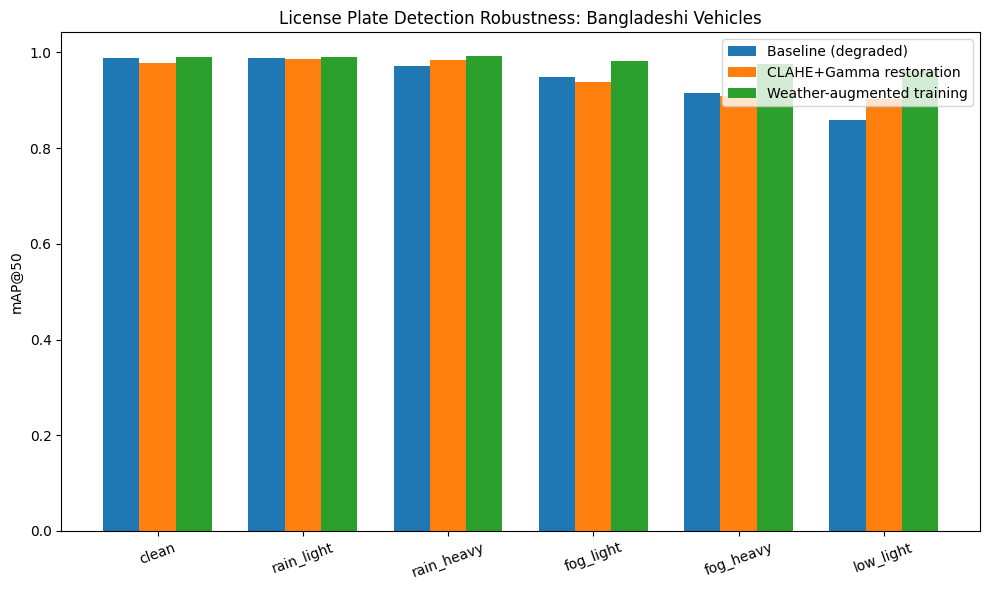

In [10]:
#Cell 8
order = ["clean"] + list(conditions.keys())
for d in [df_raw, df_restored, df_robust]:
    d["condition"] = pd.Categorical(d["condition"], categories=order, ordered=True)
    d.sort_values("condition", inplace=True); d.reset_index(drop=True, inplace=True)

final = pd.DataFrame({
    "condition": order,
    "mAP50_baseline": df_raw["mAP50"].values,
    "mAP50_classical_restoration": df_restored["mAP50"].values,
    "mAP50_weather_augmented": df_robust["mAP50"].values,
})
final.to_csv('/kaggle/working/final_conference_comparison.csv', index=False)
print(final)

x = range(len(order))
plt.figure(figsize=(10,6))
plt.bar([i-0.25 for i in x], final["mAP50_baseline"], width=0.25, label="Baseline (degraded)")
plt.bar(x, final["mAP50_classical_restoration"], width=0.25, label="CLAHE+Gamma restoration")
plt.bar([i+0.25 for i in x], final["mAP50_weather_augmented"], width=0.25, label="Weather-augmented training")
plt.xticks(x, order, rotation=20); plt.ylabel("mAP@50")
plt.title("License Plate Detection Robustness: Bangladeshi Vehicles")
plt.legend(); plt.tight_layout()
plt.savefig('/kaggle/working/conference_final_chart.png', dpi=200)
plt.show()